These scripts do:
1. load 16-18 data by each channel
2. train for a specific signal mass and dump model, dictionary (roc, ks, s/b)
>   {trial_0: {tpr: [...], fpr: [...], auc, auc_tr, ks-dist, ks-p-val}, ... }        



In [1]:
import json
import os, sys
import pickle
import datetime
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn import metrics
import seaborn as sns
import ROOT as rt
from scipy.stats import ks_2samp


## user define
sys.path.append(".")
sys.path.append("./Utils")
from Plotter import HistStack
from CommonTrain import *
from Model import Seq

2023-02-07 15:50:08.160405: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /cvmfs/sft.cern.ch/lcg/releases/MCGenerators/thepeg/2.2.3-6cb32/x86_64-centos7-gcc11-opt/lib/ThePEG:/cvmfs/sft.cern.ch/lcg/releases/MCGenerators/herwig++/7.2.3-90caf/x86_64-centos7-gcc11-opt/lib/Herwig:/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/jaxlib/mlir/_mlir_libs:/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/torch/lib:/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/onnxruntime/capi/:/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/tensorflow:/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/tensorfl

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
setting={}
with open('config/Settrain.json') as json_file:
    data = json.load(json_file)
    setting=data
INPUTDIR = setting["INPUTDIR"]
VERSION = setting["VERSION"]
# SIGNAL_MASSES = ["Zp-1700_CH-345", "Zp-2900_CH-345", "Zp-4100_CH-345", "Zp-2900_CH-1095", "Zp-4100_CH-1095", "Zp-4100_CH-1845"]
CHANNEL="ee"
ERA="17"

# Load data

In [3]:
time_stamp = datetime.datetime.now().strftime("%Y%m%d-%H%M")

with open(INPUTDIR+'/ee16pre/nested_dic_df.pkl', 'rb') as f:
    nested_dic_df = pickle.load(f)
with open(INPUTDIR+'/ee16post/nested_dic_df.pkl', 'rb') as f:
    nested_dic_df1 = pickle.load(f) 
with open(INPUTDIR+'/ee17/nested_dic_df.pkl', 'rb') as f:
    nested_dic_df2 = pickle.load(f) 
with open(INPUTDIR+'/ee18/nested_dic_df.pkl', 'rb') as f:
    nested_dic_df3 = pickle.load(f)   

dic_df_all = [nested_dic_df['raw'], nested_dic_df1['raw'], nested_dic_df2['raw'], nested_dic_df3['raw']]
dic_df_met_u_all = [nested_dic_df['met_u'], nested_dic_df1['met_u'], nested_dic_df2['met_u'], nested_dic_df3['met_u']]
dic_df_met_d_all = [nested_dic_df['met_d'], nested_dic_df1['met_d'], nested_dic_df2['met_d'], nested_dic_df3['met_d']]

selected_columns = [
#                     'MC1C1_pre', 'H3PP_pre', 'H3TPP_pre', 
                    'pt_lead_pre', 'mass_pre', # by auc rank
                    'MT_pre', 'pt_trail_pre', 'Zpt_pre', 'dRll_pre', 'PuppiMET_pre',
                    'dPhilMET_pre', 'dPhillMET_pre', 'U_pre', 'dPhill_pre', 'MT2_pre',
                    'JZB_pre']

dic_df, dic_df_met_u, dic_df_met_d, dic_df_train = [{} for _ in range(4)]

keys = [key for key in dic_df_all[0]]+['Zp-2500_CH-595'] # tmp

for key in keys:
    list_raw, list_met_u, list_met_d, list_train = [[] for _ in range(4)]
    for i in range(4):
        try:
            list_raw.append(dic_df_all[i][key])
            list_met_u.append(dic_df_met_u_all[i][key])
            list_met_d.append(dic_df_met_d_all[i][key])
            list_train.append(dic_df_all[i][key][selected_columns])
        except:
            print("missing:", key, i)
    dic_df[key]=pd.concat(list_raw, ignore_index=True)
    dic_df_met_u[key]=pd.concat(list_met_u, ignore_index=True)
    dic_df_met_d[key]=pd.concat(list_met_d, ignore_index=True)
    dic_df_train[key]=pd.concat(list_train, ignore_index=True)
#     print(key)
    
print(dic_df["TT"].columns)
print(dic_df_met_u["TT"].columns)

missing: Zp-1700_CH-345 1
missing: Zp-1700_CH-595 1
missing: Zp-1700_CH-595 3
missing: Zp-2500_CH-845 3
missing: Zp-2100_CH-345 3
missing: Zp-2900_CH-595 3
missing: Zp-3300_CH-845 1
missing: Zp-3300_CH-845 2
missing: Zp-3300_CH-845 3
missing: Zp-2500_CH-595 0
Index(['MET_pre', 'MET_phi_pre', 'PuppiMET_pre', 'PuppiMET_phi_pre',
       'mass_pre', 'pt_lead_pre', 'pt_trail_pre', 'eta_lead_pre',
       'eta_trail_pre', 'phi_lead_pre', 'phi_trail_pre', 'U_pre', 'JZB_pre',
       'dPhill_pre', 'dPhilMET_pre', 'MT_pre', 'MT2_pre', 'Zpt_pre',
       'dRll_pre', 'dPhillMET_pre', 'nbjet_pre', 'nbjetflav_pre',
       'btag_score_pre', 'nvertices_pre', 'genweight_u_pre', 'genweight_d_pre',
       'genweight_pre', 'puweight_pre', 'puweight_u_pre', 'puweight_d_pre',
       'l1prefiring_pre', 'l1prefiring_u_pre', 'l1prefiring_d_pre',
       'effSF_pre', 'effSF_u_pre', 'effSF_d_pre', 'topSF_pre', 'topSFAlt_pre',
       'MC1C1_pre', 'H3PP_pre', 'H3TPP_pre', 'pdf1_ee_pre', 'pdf2_ee_pre',
       'pdf3_ee

In [4]:
def get_binary(sig_key):
    # x: sig and all bkgs concatenated
    x = dic_df_train[sig_key].copy(deep=True)
    w_sig = np.empty(0)
    w_bkg = np.empty(0)
    w_bkg_raw = np.empty(0)
    for k in dic_df_train:
        # filter data out
        if "Data" in k:
            continue
#         df1 = pd.DataFrame()
#         df1["tot_weight"]=dic_df[k]["genweight_pre"]
#         for s in sys:
#             df1["tot_weight"]*=dic_df[k][s] 
        w_df = dic_df[k]["weight"].copy(deep=True)
            
        if k==sig_key:
            w_df/=dic_df[k]["genweight_pre"][0] # temp: sig weight: ~1
            w_sig = np.append(w_sig, w_df.to_numpy())
        if "Zp" not in k:
            x = np.concatenate([x, dic_df_train[k]], axis=0)
            # weight customization
            if k=="WW" or k=="DY":
                w_bkg = np.append(w_bkg, 10*w_df.to_numpy())
                w_bkg_raw = np.append(w_bkg_raw, w_df.to_numpy())
            else:    
                w_bkg = np.append(w_bkg, w_df.to_numpy())     
                w_bkg_raw = np.append(w_bkg_raw, w_df.to_numpy())     
    print("unweighted #sig:", w_sig.shape[0])
    print("unweighted #all bkg:", w_bkg.shape[0])
    print("weighted #sig:", np.sum(w_sig))
    print("weighted #all bkg:", np.sum(w_bkg))
    print("weighted #all bkg raw:", np.sum(w_bkg_raw))
    
    tot_sig = dic_df_train[sig_key].shape[0]
    tot_bkgs = x.shape[0] - tot_sig        
    y_sig = np.full((tot_sig,1), 1)
    y_bkgs = np.full((tot_bkgs,1), 0) 

    # class weight: scale to bkg
    classweight = np.sum(w_bkg)/np.sum(w_sig)
    w_sig *= classweight
    
    print("scaled #sig:", np.sum(w_sig))
    print("scaled #all bkg:", np.sum(w_bkg))    
    
    w = np.concatenate((w_sig, w_bkg), axis=0)
    w_raw = np.concatenate((w_sig, w_bkg_raw), axis=0)
    y = np.concatenate((y_sig, y_bkgs), axis=0) 
    
    return x, y, w, w_raw

# get_binary("Zp-2500")
get_binary("Zp-2500_CH-345")



unweighted #sig: 42744
unweighted #all bkg: 932476
weighted #sig: 55.60137980987973
weighted #all bkg: 51065.366263796896
weighted #all bkg raw: 32131.932339260304
scaled #sig: 51065.3662637969
scaled #all bkg: 51065.366263796896


(array([[ 4.64455902e+02,  5.02502228e+02,  8.66727478e+02, ...,
          2.89402509e+00,  6.29022789e+01, -2.81498260e+02],
        [ 3.18120117e+02,  4.87977600e+02,  6.04432068e+02, ...,
          2.63354492e+00,  1.44998611e+02, -1.06059128e+02],
        [ 5.25815308e+02,  6.93648071e+02,  7.56614441e+02, ...,
          2.72155762e+00,  1.44165573e+02, -3.22934296e+02],
        ...,
        [ 2.11897614e+02,  2.30401031e+02,  2.08485352e+02, ...,
          1.92311096e+00,  2.82069892e-01,  1.02650131e+02],
        [ 5.04007202e+02,  5.04952881e+02,  9.22221497e+02, ...,
          3.11454511e+00,  5.41274369e-01, -3.47891174e+02],
        [ 9.28446503e+01,  1.08654175e+02,  2.00520065e+02, ...,
          1.59692383e+00,  6.74850998e+01,  1.50619125e+02]], dtype=float32),
 array([[1],
        [1],
        [1],
        ...,
        [0],
        [0],
        [0]]),
 array([0.9784705 , 0.71835118, 1.02971303, ..., 0.59282799, 0.60589966,
        0.49962265]),
 array([0.9784705 , 0.7183

In [5]:
# from tensorflow.python.client import device_lib
# print(device_lib.list_local_devices())

# Training

unweighted #sig: 42744
unweighted #all bkg: 932476
weighted #sig: 55.60137980987973
weighted #all bkg: 51065.366263796896
weighted #all bkg raw: 32131.932339260304
scaled #sig: 51065.3662637969
scaled #all bkg: 51065.366263796896
mean: [151.79867462 238.24277738 273.15254721  80.01411683 114.10999046
   2.64987392 156.7670098    1.91803583   1.91677379 151.06573877
   2.32614157  46.53706349  36.95574831]
var: [7.05735784e+03 1.96341592e+04 2.59892263e+04 2.05945967e+03
 6.50008569e+03 4.63227469e-01 4.77022920e+03 1.05155412e+00
 9.64881608e-01 1.24579408e+04 4.96220215e-01 2.79340402e+03
 1.38495625e+04]
Epoch 1/5
953/953 [==============================] - 152s 158ms/step - loss: 0.0714 - accuracy: 0.7299 - val_loss: 0.0640 - val_accuracy: 0.6711
Epoch 2/5
953/953 [==============================] - 3s 3ms/step - loss: 0.0594 - accuracy: 0.6664 - val_loss: 0.0524 - val_accuracy: 0.7774
Epoch 3/5
953/953 [==============================] - 3s 3ms/step - loss: 0.0512 - accuracy: 0.7847 -

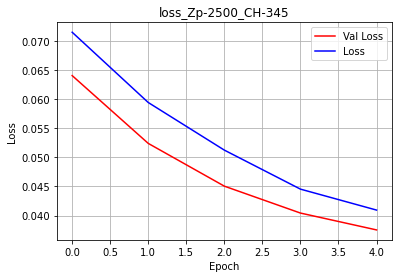

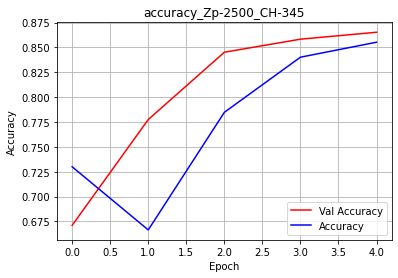

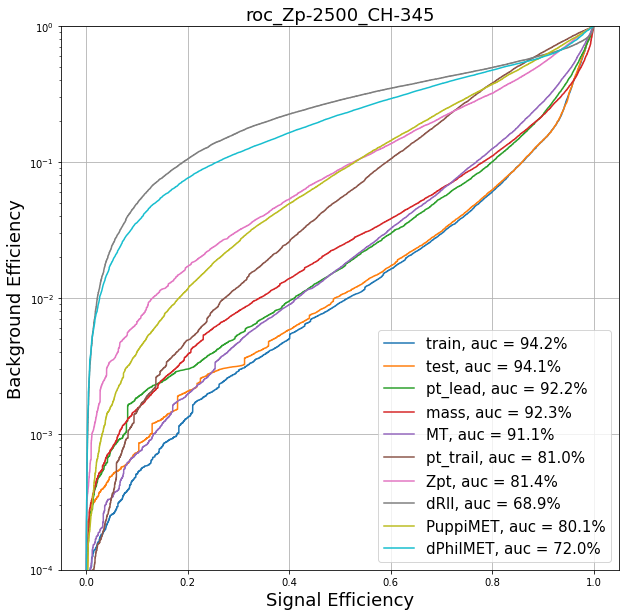

2023-02-07 15:56:39.669020: W tensorflow/python/util/util.cc:368] Sets are not currently considered sequences, but this may change in the future, so consider avoiding using them.
Info in <TCanvas::Print>: pdf file Outputs/ee/Dedicated/check_withweight0_score.pdf has been created


In [9]:
OUTDIR = 'Outputs/'+CHANNEL+'/Dedicated'
os.system('mkdir -p '+OUTDIR)

nbin=20

# model_masses = ['Zp-1700_CH-345', 'Zp-2500_CH-345', 'Zp-2900_CH-345', 'Zp-3300_CH-345', 'Zp-4100_CH-345']
# model_masses = [m for m in dic_df_train if 'Zp' in m] # if want to run all
model_masses = ['Zp-2500_CH-345']
# %matplotlib inline
rt.gROOT.SetBatch(rt.kTRUE)

for model_mass in model_masses:
    
    file_postfix = model_mass+'_'+VERSION
    
    x, y, w, w_raw = get_binary(model_mass)

    # binalize
    lb = preprocessing.LabelBinarizer()
    lb.fit(y)
    lb.classes_
    y=lb.transform(y)

    # split train, test
    x_train, x_test, y_train, y_test, w_train, w_test, w_train_raw, w_test_raw = train_test_split(x, y, w, w_raw, test_size=0.5)

    # scale
    Transformer = preprocessing.StandardScaler()
    Transformer.fit(x)
    print('mean:',Transformer.mean_)
    print('var:',Transformer.var_)        
    x_train = Transformer.transform(x_train)
    x_test = Transformer.transform(x_test)
    pickle.dump(Transformer, open(OUTDIR+'/scaler_'+file_postfix+'.pkl','wb'))

    dic_df_scale={}
    for key2 in dic_df_train:
#             dic_df_scale[key2].append(dic_df_train[key2])       
        dic_df_scale[key2] = Transformer.transform(dic_df_train[key2])       
#     sess = tf.compat.v1.Session(config=tf.compat.v1.ConfigProto(log_device_placement=True))
    
    # training 
    epochs = 250
    batch = 512
    opt = keras.optimizers.SGD(learning_rate=0.01, decay=1e-6)
    early_stopping = keras.callbacks.EarlyStopping(patience=20)

    n_input = dic_df_train[key].shape[1]
    model = Seq(n_input, n_input, 1, tf.nn.sigmoid)
    model.compile(loss='binary_crossentropy', 
                  optimizer=opt, 
                  metrics=['accuracy'])

    log_dir = "logs/fit/mm_multiclass_" + time_stamp
    tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

    dic_nested_roc = {}        
    dic_nested_soverb = {}        
    for i in range(1): # number of trials

        history = model.fit(x_train, y_train, verbose=1,
                         epochs=epochs, 
                         batch_size=batch,  
#                              class_weight={0:classweight_sig, 1:classweight_bkgs}, 
                         sample_weight=w_train,   
                         validation_data=(x_test,y_test,w_test), 
#                              validation_data=(x_test,y_test), 
                         callbacks=[early_stopping, tensorboard_callback])


        # evaluate
        TrainScore = model.evaluate(x_train, y_train, batch_size=x_train.shape[0], verbose=0)
        TestScore = model.evaluate(x_test, y_test, batch_size=x_test.shape[0], verbose=0)
        print('Train Loss :', TrainScore[0])
        print('Train Acc :', TrainScore[1])
        print('Test Loss :', TestScore[0])
        print('Test Acc :', TestScore[1])
        train_predict = model.predict(x_train, batch_size=x_train.shape[0])
        test_predict = model.predict(x_test, batch_size=x_test.shape[0])

        # save 
        model.save(OUTDIR+'/model_binary_'+file_postfix)
        with open(OUTDIR+'/history_binary_'+file_postfix, 'wb') as file_pi:
            pickle.dump(history.history, file_pi)        
        # loss
        pl2 = save_loss(model_mass, history, file_name=OUTDIR+'/loss_'+file_postfix+'.pdf')
        #pl2.show()
        #accuracy
        pl3 = save_accuracy(model_mass, history, file_name=OUTDIR+'/accuracy_'+file_postfix+'.pdf')
        #pl3.show()
        
        df_val = pd.DataFrame()
        df_val['y_test'] = y_test[:,0]
        df_val['test_predict'] = test_predict
        df_val['w_test_raw'] = w_test_raw
        df_tr = pd.DataFrame()
        df_tr['y_train'] = y_train[:,0]
        df_tr['train_predict'] = train_predict
        df_tr['w_train_raw'] = w_train_raw
        
        pl4, tpr, fpr, auc, tpr1, fpr1, auc1=save_roc(model_mass, df_val, df_tr, x_train, selected_columns, file_name=OUTDIR+'/roc_'+file_postfix+'.pdf')
        dic_roc = {}
        dic_roc['tpr'] = tpr
        dic_roc['fpr'] = fpr
        dic_roc['auc'] = auc
        dic_roc['auc_tr'] = auc1        
        sig_stat, sig_pval = ks_2samp(df_val.query('y_test==1')['test_predict'], df_tr.query('y_train==1')['train_predict'])
        bkg_stat, bkg_pval = ks_2samp(df_val.query('y_test==0')['test_predict'], df_tr.query('y_train==0')['train_predict'])
        dic_roc['sig_stat'] = sig_stat
        dic_roc['sig_pval'] = sig_pval
        dic_roc['bkg_stat'] = bkg_stat
        dic_roc['bkg_pval'] = bkg_pval        
        dic_nested_roc['trial_'+str(i)] = dic_roc

        # predict
        dic_predict={}
        for key3 in dic_df_scale:
            dic_predict[key3] = model.predict(dic_df_scale[key3], batch_size=dic_df_scale[key3].shape[0])

        dic_predict_sort={}
        for key4 in dic_predict:
            new_df = dic_df[key4].copy(deep=True).reset_index(drop='True')
            new_df['score'] = dic_predict[key4]            
            dic_predict_sort[key4] = new_df
        ERA = 'ee17'
        hist=HistStack(dic_predict_sort, 'score', 'weight', nbin, 0, 1)                         
        c1=hist.draw_hist(key, ERA, file_name=OUTDIR+'/check_withweight'+str(i), is_dnn=True)

        yields = hist.get_yields_by_bin()
        dic_nested_soverb['trial_'+str(i)] = np.array(yields[model_mass])/np.array(yields['bkg'])

    with open(OUTDIR+'/nested_dic_roc_trials'+file_postfix+'.pkl', 'wb') as f:
        pickle.dump(dic_nested_roc, f)  
    with open(OUTDIR+'/nested_dic_soverb_trials'+file_postfix+'.pkl', 'wb') as f:
        pickle.dump(dic_nested_soverb, f) 

           